#### Спектр
$$\frac{d\,\Gamma}{dE} = C p_e (E + m_e) (E_0 - E)\sqrt{(E_0 - E)^2 - m_{\nu}^2}\,\Theta{(E_0 - E - m_{\nu})}$$
#### Максимальная кин.энергия электрона  
Получается из $\Theta{(E_0 - E - m_{\nu})}$
$$E_{max}(m_{\nu}) = E_0 - m_{\nu}$$


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

m_e = 511e3        # 511 кэВ
E_0 = 18.575e3     # 18.575 кэВ

def dGamma_dE(E, m_nu, C=1.):
    """
    beta decay spectrum without normalization
    """
    E = np.asarray(E, dtype=float)
    p_e = np.sqrt(E**2 + 2*m_e*E)
    deltaE = E_0 - E
    sqrt_term = np.zeros_like(E)
    sqrt_term[deltaE >= m_nu] = np.sqrt(deltaE[deltaE >= m_nu]**2 - m_nu**2) # deltaE >= m_nu is result of theta-function
    return C * p_e * (E + m_e) * deltaE * sqrt_term

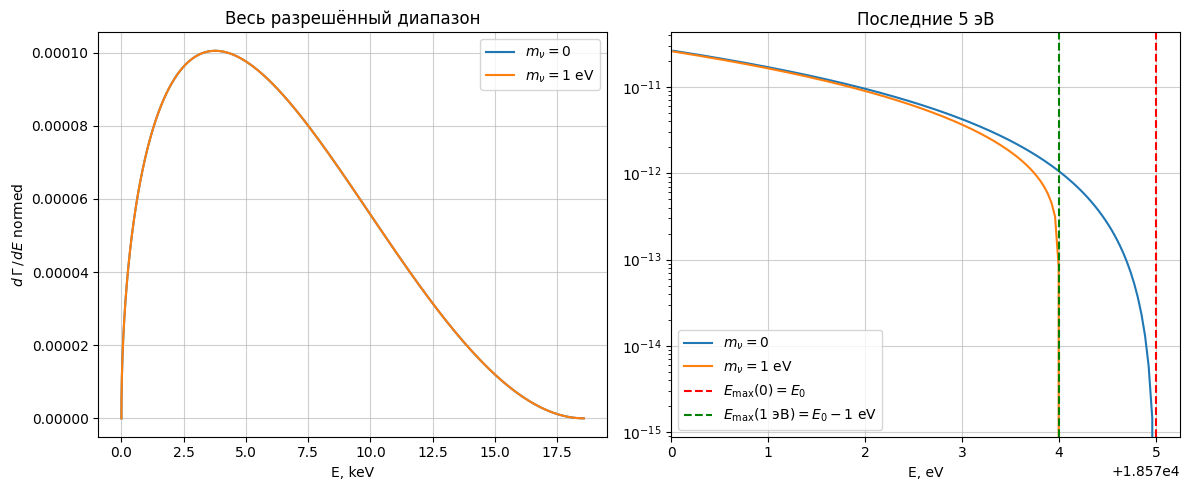

In [36]:
E_all = np.linspace(0, E_0, 500000)

spectrum0   = dGamma_dE(E_all, m_nu=0.0)
norm = np.trapezoid(spectrum0, E_all)   # calculate norm
# equal norm for both spectra
spectrum0_normed = spectrum0 / norm
spectrum1_normed = dGamma_dE(E_all, m_nu=1.0) / norm

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(E_all/1e3, spectrum0_normed, label=r'$m_\nu = 0$')
axs[0].plot(E_all/1e3, spectrum1_normed, label=r'$m_\nu = 1$ eV')
axs[0].set_xlabel('E, keV')
axs[0].set_ylabel(r'$d\,\Gamma\,/\,dE$ normed')
axs[0].set_title('Весь разрешённый диапазон')
axs[0].legend()
axs[0].grid(alpha=0.6)

mask = (E_all >= E_0 - 5) & (E_all <= E_0)
axs[1].plot(E_all[mask], spectrum0_normed[mask], label=r'$m_\nu = 0$')
axs[1].plot(E_all[mask], spectrum1_normed[mask], label=r'$m_\nu = 1$ eV')
axs[1].set_xlabel('E, eV')
axs[1].set_title('Последние 5 эВ')
axs[1].grid(alpha=0.6)
axs[1].set_xlim(E_0 - 5)
axs[1].set_yscale("log")

axs[1].axvline(E_0, color='red', ls='--', label=r'$E_{\max}(0)=E_0$')
axs[1].axvline(E_0 - 1, color='green', ls='--', label=r'$E_{\max}(1\text{ эВ})=E_0-1$ eV')
axs[1].legend()

plt.tight_layout()
plt.show()

#### Доля всех распадов, попадающая в 1 эВ и в 5 эВ с конца
$$\frac{N(E>E_0 - \Delta E)}{N_{all}} \sim \left(\frac{\Delta E}{E_0}\right)^3$$

In [ ]:
def fraction_from_end(m_nu, delta_E):
    E_tail = np.linspace(E_0 - delta_E, E_0 - m_nu, 1000)
    spectrum_tail = dGamma_dE(E_tail, m_nu)
    
    E_all = np.linspace(0, E_0 - m_nu, 1000)
    spectrum_all = dGamma_dE(E_all, m_nu)
    return np.trapezoid(spectrum_tail, E_tail) / np.trapezoid(spectrum_all, E_all)

deltaE = [1., 5.]

for dE in deltaE:
    numerical = fraction_from_end(0., dE)
    analytical = (dE / E_0)**3
    print(f"Interval E = {dE} eV\n\tnumerical = {numerical:.3e}\n\tanalytical = {analytical:.3e}")


Interval E = 1.0 eV
	numerical = 3.516e-13
	analytical = 1.560e-13
Interval E = 5.0 eV
	numerical = 4.394e-11
	analytical = 1.950e-11


#### Свёртка с гауссом

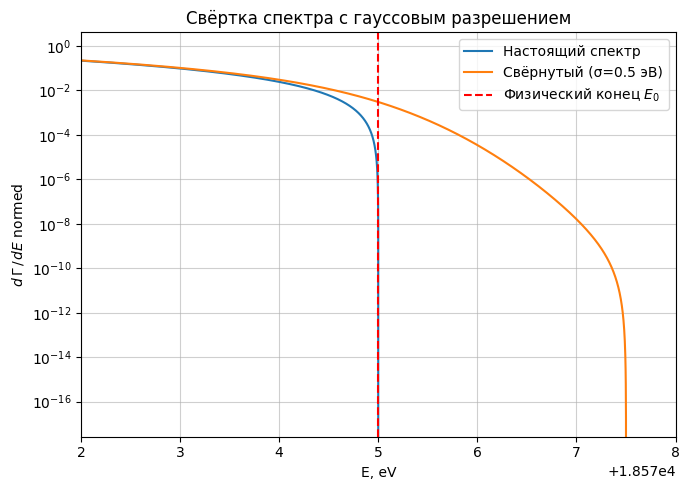

In [35]:
sigma = 0.5 

E_fine = np.linspace(E_0-10*sigma, E_0 + 10*sigma, 10000)
spectrum_fine = dGamma_dE(E_fine, m_nu=0.0)
norm_fine = np.trapezoid(spectrum_fine, E_fine)
spectrum_norm = spectrum_fine / norm_fine

dE = E_fine[1] - E_fine[0]
E_gauss = np.arange(-5*sigma, 5*sigma + dE, dE)
gauss = np.exp(-E_gauss**2 / (2*sigma**2))
gauss /= np.trapezoid(gauss, E_gauss) # norm gauss 

spectrum_conv = np.convolve(spectrum_norm, gauss, mode='same') * dE

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(E_fine, spectrum_norm,  label='Настоящий спектр')
ax.plot(E_fine, spectrum_conv,  label='Свёрнутый (σ=0.5 эВ)')
ax.axvline(E_0, color='red', ls='--', label=r'Физический конец $E_0$')
ax.set_xlim(E_0-3, E_0+3)
ax.set_xlabel('E, eV')
ax.set_ylabel(r'$d\,\Gamma\,/\,dE$ normed')
ax.set_title('Свёртка спектра с гауссовым разрешением')
ax.legend()
ax.set_yscale("log")
ax.grid(alpha=0.6)
plt.tight_layout()
plt.show()